# Baseline Experiments for Skill-to-Issue Matching

## Objective
Compare two simple approaches for matching developer profiles to open-source issues:

1. **Keyword Overlap** — compares the skills in a profile with the words in an issue.
2. **TF-IDF + Cosine Similarity** — represents profile and issue text as TF-IDF vectors and compares their cosine similarity.

We use a small handmade dataset with manually defined relevance labels. Both approaches are evaluated against the same labels.

> These are experimental baselines, not replacements for the production matching service.


In [11]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid")


## 1. Handmade dataset

The dataset contains four developer profiles and eight sample issues. Each profile has a manually defined set of relevant issue IDs.

These labels act as a small reference set for comparing the rankings. They are illustrative, not a substitute for evaluation on real contributor data.


In [12]:
profiles = {
    "python_backend": {
        "skills": ["python", "fastapi", "sql", "api", "backend"],
        "description": "Python backend developer building REST APIs and database integrations."
    },
    "frontend_react": {
        "skills": ["javascript", "react", "typescript", "css", "frontend"],
        "description": "Frontend developer working with React, TypeScript, JavaScript and CSS."
    },
    "ml_nlp": {
        "skills": ["python", "machine learning", "nlp", "pandas", "scikit-learn"],
        "description": "Machine learning developer interested in NLP, data processing and Python."
    },
    "java_android": {
        "skills": ["java", "android", "kotlin", "mobile", "sqlite"],
        "description": "Mobile developer building Android applications with Java and Kotlin."
    }
}

issues = [
    {
        "id": "I1",
        "title": "Add pagination to FastAPI endpoints",
        "body": "Implement pagination and filtering for Python REST API endpoints.",
        "labels": ["backend", "python"]
    },
    {
        "id": "I2",
        "title": "Fix React component state handling",
        "body": "Resolve state update bugs in reusable React and TypeScript components.",
        "labels": ["frontend", "javascript"]
    },
    {
        "id": "I3",
        "title": "Improve text classification pipeline",
        "body": "Use Python and scikit-learn to improve NLP text preprocessing and classification.",
        "labels": ["machine-learning", "nlp"]
    },
    {
        "id": "I4",
        "title": "Add SQLite persistence to Android app",
        "body": "Implement local database storage for an Android application using Java.",
        "labels": ["android", "java"]
    },
    {
        "id": "I5",
        "title": "Optimize SQL queries in backend service",
        "body": "Improve database query performance and API response times in the backend.",
        "labels": ["backend", "database"]
    },
    {
        "id": "I6",
        "title": "Build responsive navigation menu",
        "body": "Create a responsive CSS navigation menu with accessible frontend interactions.",
        "labels": ["frontend", "css"]
    },
    {
        "id": "I7",
        "title": "Clean and analyze tabular datasets",
        "body": "Use pandas and Python to clean datasets and prepare data for machine learning.",
        "labels": ["data", "python"]
    },
    {
        "id": "I8",
        "title": "Add Kotlin support to mobile module",
        "body": "Extend the Android mobile module with Kotlin compatibility and tests.",
        "labels": ["android", "kotlin"]
    }
]

# Manually assigned relevant issues for each profile.
relevant_issues = {
    "python_backend": {"I1", "I5"},
    "frontend_react": {"I2", "I6"},
    "ml_nlp": {"I3", "I7"},
    "java_android": {"I4", "I8"}
}

profiles_df = pd.DataFrame([
    {"profile": name, "skills": data["skills"], "description": data["description"]}
    for name, data in profiles.items()
])

issues_df = pd.DataFrame(issues)

display(profiles_df)
display(issues_df)


,profile,skills,description
0,python_backend,"[python, fastapi, sql, api, backend]",Python backend developer building REST APIs an...
1,frontend_react,"[javascript, react, typescript, css, frontend]","Frontend developer working with React, TypeScr..."
2,ml_nlp,"[python, machine learning, nlp, pandas, scikit...","Machine learning developer interested in NLP, ..."
3,java_android,"[java, android, kotlin, mobile, sqlite]",Mobile developer building Android applications...


,id,title,body,labels
0,I1,Add pagination to FastAPI endpoints,Implement pagination and filtering for Python ...,"[backend, python]"
1,I2,Fix React component state handling,Resolve state update bugs in reusable React an...,"[frontend, javascript]"
2,I3,Improve text classification pipeline,Use Python and scikit-learn to improve NLP tex...,"[machine-learning, nlp]"
3,I4,Add SQLite persistence to Android app,Implement local database storage for an Androi...,"[android, java]"
4,I5,Optimize SQL queries in backend service,Improve database query performance and API res...,"[backend, database]"
5,I6,Build responsive navigation menu,Create a responsive CSS navigation menu with a...,"[frontend, css]"
6,I7,Clean and analyze tabular datasets,Use pandas and Python to clean datasets and pr...,"[data, python]"
7,I8,Add Kotlin support to mobile module,Extend the Android mobile module with Kotlin c...,"[android, kotlin]"


## 2. Baseline A — Keyword overlap

For each profile and issue, count how many profile skills appear in the issue text. Divide by the number of profile skills to normalize the score.

This is intentionally simple. It does not understand synonyms or semantic relationships.


In [13]:
def tokenize(text):
    return set(re.findall(r"[a-zA-Z0-9+#.]+", text.lower()))

def keyword_overlap(profile, issue):
    profile_terms = set(profile["skills"])
    issue_text = f"{issue['title']} {issue['body']} {' '.join(issue['labels'])}"
    issue_terms = tokenize(issue_text)

    matched = sum(
        1 for skill in profile_terms
        if skill.lower() in issue_terms or skill.lower() in issue_text.lower()
    )
    return matched / max(len(profile_terms), 1)



## 3. Baseline B — TF-IDF cosine similarity

TF-IDF gives more weight to terms that are informative across the corpus. Cosine similarity compares the profile text with each issue's text.

We use the same profile and issue examples as the keyword baseline.


In [14]:
profile_names = list(profiles.keys())
issue_texts = [
    f"{issue['title']} {issue['body']} {' '.join(issue['labels'])}"
    for issue in issues
]
profile_texts = [
    f"{data['description']} {' '.join(data['skills'])}"
    for data in profiles.values()
]

corpus = profile_texts + issue_texts
vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = vectorizer.fit_transform(corpus)

profile_vectors = tfidf_matrix[:len(profile_texts)]
issue_vectors = tfidf_matrix[len(profile_texts):]

tfidf_scores = cosine_similarity(profile_vectors, issue_vectors)

keyword_scores = np.array([
    [keyword_overlap(profiles[p], issue) for issue in issues]
    for p in profile_names
])

keyword_df = pd.DataFrame(
    keyword_scores,
    index=profile_names,
    columns=[issue["id"] for issue in issues]
)

tfidf_df = pd.DataFrame(
    tfidf_scores,
    index=profile_names,
    columns=[issue["id"] for issue in issues]
)

display(keyword_df.round(3))
display(tfidf_df.round(3))


,I1,I2,I3,I4,I5,I6,I7,I8
python_backend,0.8,0.0,0.2,0.2,0.6,0.0,0.2,0.0
frontend_react,0.0,0.8,0.0,0.0,0.0,0.4,0.0,0.0
ml_nlp,0.2,0.0,0.6,0.0,0.0,0.0,0.6,0.0
java_android,0.0,0.2,0.0,0.6,0.0,0.0,0.0,0.6


,I1,I2,I3,I4,I5,I6,I7,I8
python_backend,0.386,0.000,0.053,0.044,0.451,0.000,0.111,0.00
frontend_react,0.000,0.433,0.000,0.000,0.000,0.289,0.000,0.00
ml_nlp,0.105,0.000,0.444,0.000,0.000,0.000,0.373,0.00
java_android,0.000,0.000,0.000,0.465,0.000,0.000,0.000,0.57


## 4. Evaluate ranking quality

We use **Precision@3**: the fraction of the top three ranked issues that are manually labelled relevant for a profile.

We also calculate **Mean Reciprocal Rank (MRR)**: the reciprocal rank of the first relevant issue, averaged across profiles. Higher values indicate that a relevant issue tends to appear earlier.

These metrics evaluate ranking order rather than comparing raw scores, which have different scales across the two methods.


In [15]:
def evaluate(scores, k=3):
    rows = []

    for profile_idx, profile_name in enumerate(profile_names):
        ranked_indices = np.argsort(scores[profile_idx])[::-1]
        ranked_ids = [issues[i]["id"] for i in ranked_indices]

        relevant = relevant_issues[profile_name]
        top_k = ranked_ids[:k]
        precision_at_k = sum(issue_id in relevant for issue_id in top_k) / k

        reciprocal_rank = 0.0
        for rank, issue_id in enumerate(ranked_ids, start=1):
            if issue_id in relevant:
                reciprocal_rank = 1 / rank
                break

        rows.append({
            "profile": profile_name,
            f"Precision@{k}": precision_at_k,
            "Reciprocal Rank": reciprocal_rank
        })

    return pd.DataFrame(rows)

keyword_metrics = evaluate(keyword_scores)
tfidf_metrics = evaluate(tfidf_scores)

keyword_metrics["method"] = "Keyword overlap"
tfidf_metrics["method"] = "TF-IDF cosine"

metrics = pd.concat([keyword_metrics, tfidf_metrics], ignore_index=True)
display(metrics)

summary = (
    metrics.groupby("method")[["Precision@3", "Reciprocal Rank"]]
    .mean()
    .sort_values("Precision@3", ascending=False)
)

display(summary.round(3))


,profile,Precision@3,Reciprocal Rank,method
0,python_backend,0.666667,1.0,Keyword overlap
1,frontend_react,0.666667,1.0,Keyword overlap
2,ml_nlp,0.666667,1.0,Keyword overlap
3,java_android,0.666667,1.0,Keyword overlap
4,python_backend,0.666667,1.0,TF-IDF cosine
5,frontend_react,0.666667,1.0,TF-IDF cosine
6,ml_nlp,0.666667,1.0,TF-IDF cosine
7,java_android,0.666667,1.0,TF-IDF cosine


,Precision@3,Reciprocal Rank
method,,
Keyword overlap,0.667,1.0
TF-IDF cosine,0.667,1.0


## 5. Visualize the results

The first chart compares average ranking metrics. The heatmaps show the score assigned to each profile-issue pair by each baseline.


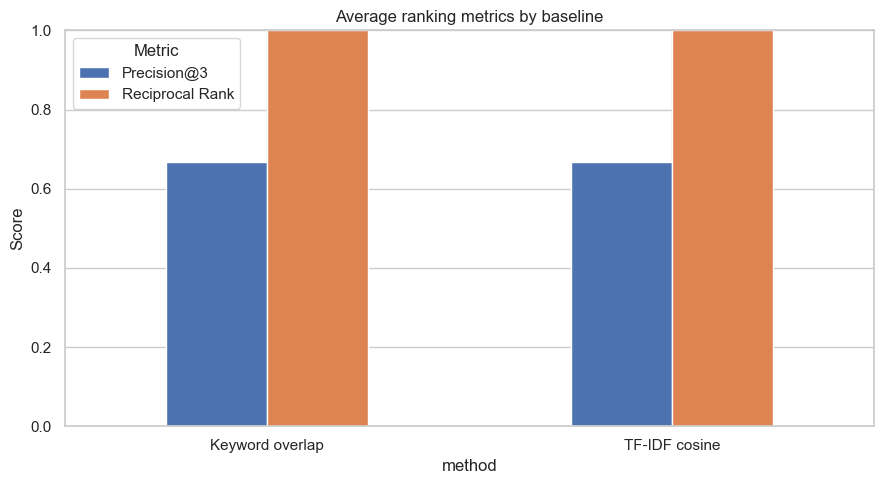

In [16]:
summary.plot(kind="bar", figsize=(9, 5))
plt.title("Average ranking metrics by baseline")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()


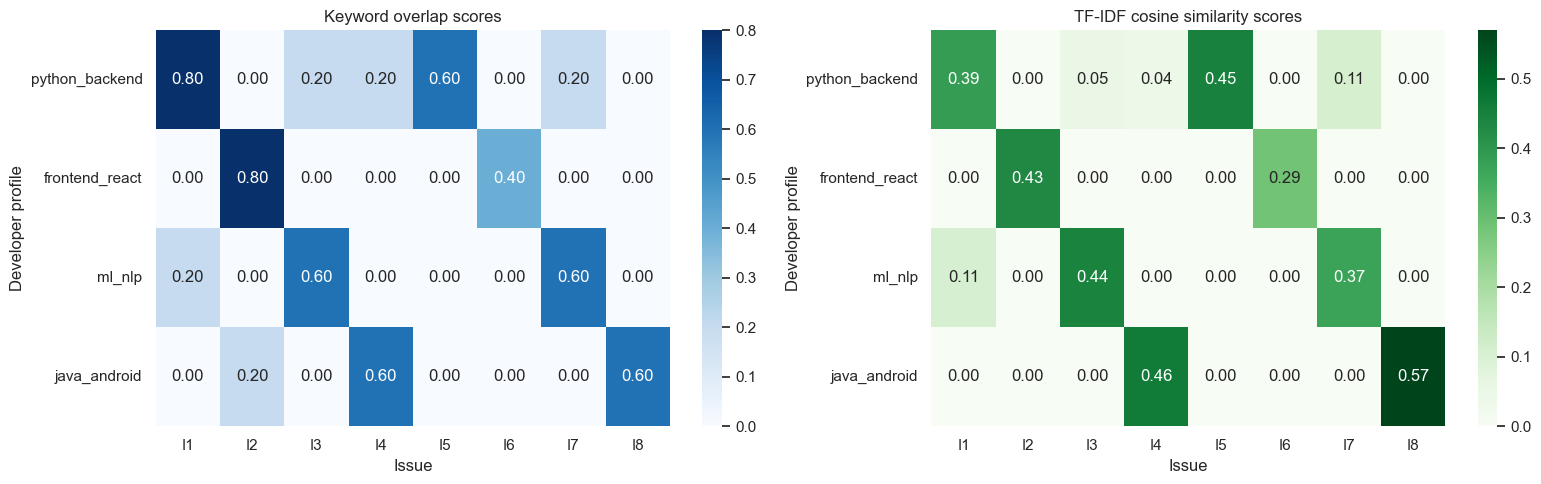

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(keyword_df, annot=True, fmt=".2f", cmap="Blues", ax=axes[0])
axes[0].set_title("Keyword overlap scores")
axes[0].set_xlabel("Issue")
axes[0].set_ylabel("Developer profile")

sns.heatmap(tfidf_df, annot=True, fmt=".2f", cmap="Greens", ax=axes[1])
axes[1].set_title("TF-IDF cosine similarity scores")
axes[1].set_xlabel("Issue")
axes[1].set_ylabel("Developer profile")

plt.tight_layout()
plt.show()


## 6. Compare top-ranked issues

Inspect the top three issues returned by each method for every profile. This makes it easier to identify false positives and differences in ranking.


In [18]:
def top_matches(scores, method_name, k=3):
    rows = []
    for profile_idx, profile_name in enumerate(profile_names):
        ranked_indices = np.argsort(scores[profile_idx])[::-1][:k]
        for rank, issue_idx in enumerate(ranked_indices, start=1):
            issue = issues[issue_idx]
            rows.append({
                "method": method_name,
                "profile": profile_name,
                "rank": rank,
                "issue_id": issue["id"],
                "title": issue["title"],
                "score": float(scores[profile_idx][issue_idx]),
                "manually_relevant": issue["id"] in relevant_issues[profile_name]
            })
    return rows

top_matches_df = pd.DataFrame(
    top_matches(keyword_scores, "Keyword overlap") +
    top_matches(tfidf_scores, "TF-IDF cosine")
)

display(top_matches_df)


,method,profile,rank,issue_id,title,score,manually_relevant
0,Keyword overlap,python_backend,1,I1,Add pagination to FastAPI endpoints,0.800000,True
1,Keyword overlap,python_backend,2,I5,Optimize SQL queries in backend service,0.600000,True
2,Keyword overlap,python_backend,3,I7,Clean and analyze tabular datasets,0.200000,False
3,Keyword overlap,frontend_react,1,I2,Fix React component state handling,0.800000,True
4,Keyword overlap,frontend_react,2,I6,Build responsive navigation menu,0.400000,True
5,Keyword overlap,frontend_react,3,I8,Add Kotlin support to mobile module,0.000000,False
6,Keyword overlap,ml_nlp,1,I7,Clean and analyze tabular datasets,0.600000,True
7,Keyword overlap,ml_nlp,2,I3,Improve text classification pipeline,0.600000,True
8,Keyword overlap,ml_nlp,3,I1,Add pagination to FastAPI endpoints,0.200000,False
9,Keyword overlap,java_android,1,I8,Add Kotlin support to mobile module,0.600000,True


## 7. Conclusion

The preferred first baseline should be selected using the evaluation results above, not assumed in advance.

The following cell reports which method has the higher average Precision@3 and MRR on this handmade dataset.

### Limitations
- The dataset is small and manually constructed.
- Relevance labels are subjective and may not reflect real contributor decisions.
- Keyword overlap is sensitive to exact wording.
- TF-IDF captures term importance but does not understand meaning or technical context.
- Neither baseline considers issue freshness, difficulty, language preferences, repository activity, or contributor experience.
- Results on this dataset should not be treated as proof of performance on real GitHub issues.


In [19]:
best_precision = summary["Precision@3"].idxmax()
best_mrr = summary["Reciprocal Rank"].idxmax()

print("Average Precision@3:")
print(summary["Precision@3"].round(3).to_string())

print("\nAverage MRR:")
print(summary["Reciprocal Rank"].round(3).to_string())

print(f"\nHigher Precision@3 on this dataset: {best_precision}")
print(f"Higher MRR on this dataset: {best_mrr}")

if best_precision == best_mrr:
    print(
        f"\nInitial recommendation: implement {best_precision} first as the "
        "simpler baseline, then compare it with the other method on a larger "
        "labelled dataset."
    )
else:
    print(
        "\nThe metrics disagree. Inspect the per-profile rankings and false "
        "positives before choosing a baseline. Do not select a method from "
        "one metric alone."
    )


Average Precision@3:
method
Keyword overlap    0.667
TF-IDF cosine      0.667
\nAverage MRR:
method
Keyword overlap    1.0
TF-IDF cosine      1.0
\nHigher Precision@3 on this dataset: Keyword overlap
Higher MRR on this dataset: Keyword overlap
\nInitial recommendation: implement Keyword overlap first as the simpler baseline, then compare it with the other method on a larger labelled dataset.
